In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("feature_engineering_practice_dataset.csv")

In [5]:
df.head()
df.shape
df.info()



<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   customer_id               100 non-null    str    
 1   age                       100 non-null    int64  
 2   gender                    100 non-null    str    
 3   city                      100 non-null    str    
 4   education                 97 non-null     str    
 5   monthly_income            97 non-null     float64
 6   purchases                 100 non-null    int64  
 7   avg_order_value           97 non-null     float64
 8   website_visits            100 non-null    int64  
 9   days_since_last_purchase  100 non-null    int64  
 10  discount_used             100 non-null    str    
 11  membership                100 non-null    str    
 12  satisfaction_score        100 non-null    int64  
dtypes: float64(2), int64(5), str(6)
memory usage: 10.3 KB


In [6]:

target = df["avg_order_value"]
numerical_cols = [
    "age",
    "monthly_income",
    "purchases",
    "website_visits",
    "days_since_last_purchase",
    "satisfaction_score"
]

categorical_cols = [
    "gender",
    "city",
    "education",
    "discount_used",
    "membership"
]

X = df[numerical_cols + categorical_cols]
y = df["avg_order_value"]

print("Numerical columns:")
print(numerical_cols)

print("\nCategorical columns:")
print(categorical_cols)

print("\nTarget:")
print(y.head())

Numerical columns:
['age', 'monthly_income', 'purchases', 'website_visits', 'days_since_last_purchase', 'satisfaction_score']

Categorical columns:
['gender', 'city', 'education', 'discount_used', 'membership']

Target:
0    3840.88
1    2068.42
2     692.45
3    3952.59
4    2924.50
Name: avg_order_value, dtype: float64


In [13]:
print(df["avg_order_value"].isna().sum())

3


In [14]:
df = df.dropna(subset=["avg_order_value"])

In [15]:
X = df.drop(columns=["avg_order_value", "customer_id"])
y = df["avg_order_value"]

In [16]:
print(y.isna().sum())

0


In [ ]:
numerical_cols = X.select_dtypes(include="number").columns.tolist()
categorical_cols = X.select_dtypes(include="object").columns.tolist()

print("Numerical:", numerical_cols)
print("Categorical:", categorical_cols)

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

In [21]:
from sklearn.linear_model import LinearRegression

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

In [22]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['age','gender','city',...,'discount_used','membership', 'satisfaction_score']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset

In [23]:
y_pred = model.predict(X_test)

In [24]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R²  :", r2)

MAE : 1783.2515505720671
MSE : 4309691.623673498
RMSE: 2075.979678049257
R²  : -0.7227599346057323


In [25]:
before_performance = pd.DataFrame({
    "Model": ["Linear Regression - Before Feature Engineering"],
    "MAE": [mae],
    "MSE": [mse],
    "RMSE": [rmse],
    "R2": [r2]
})

before_performance

,Model,MAE,MSE,RMSE,R2
0,Linear Regression - Before Feature Engineering,1783.251551,4.309692e+06,2075.979678,-0.72276


In [26]:
before_performance.to_csv(
    "before_feature_engineering_performance.csv",
    index=False
)

In [27]:


df_fe = df.copy()

# 1. Income per Purchase
df_fe["income_per_purchase"] = (
    df_fe["monthly_income"] / (df_fe["purchases"] + 1)
)

# 2. Visits per Purchase
df_fe["visits_per_purchase"] = (
    df_fe["website_visits"] / (df_fe["purchases"] + 1)
)

# 3. Purchase Frequency
df_fe["purchase_frequency"] = (
    df_fe["purchases"] / (df_fe["days_since_last_purchase"] + 1)
)

# 4. Income per Website Visit
df_fe["income_per_visit"] = (
    df_fe["monthly_income"] / (df_fe["website_visits"] + 1)
)

# 5. Recent Customer
df_fe["is_recent_customer"] = (
    df_fe["days_since_last_purchase"] <= 30
).astype(int)

# 6. Frequent Buyer
df_fe["is_frequent_buyer"] = (
    df_fe["purchases"] >= 10
).astype(int)

# 7. High Website Engagement
df_fe["high_website_engagement"] = (
    df_fe["website_visits"] >= 20
).astype(int)

In [28]:
y_fe = df_fe["avg_order_value"]

X_fe = df_fe.drop(
    columns=["avg_order_value", "customer_id"]
)

In [29]:
numeric_features = X_fe.select_dtypes(include="number")

correlation_matrix = numeric_features.corr()

print(correlation_matrix)

                               age  monthly_income  purchases  website_visits  \
age                       1.000000       -0.004209   0.089067        0.135935   
monthly_income           -0.004209        1.000000  -0.034052        0.050542   
purchases                 0.089067       -0.034052   1.000000       -0.056567   
website_visits            0.135935        0.050542  -0.056567        1.000000   
days_since_last_purchase -0.042470        0.137523   0.056411        0.122604   
satisfaction_score        0.148159        0.029120  -0.102093        0.054121   
income_per_purchase      -0.019363        0.449726  -0.711110        0.052557   
visits_per_purchase       0.065189       -0.017983  -0.583717        0.568146   
purchase_frequency        0.108006       -0.028756   0.229363       -0.043082   
income_per_visit         -0.210377        0.353915  -0.047067       -0.665518   
is_recent_customer       -0.020480       -0.176065   0.039842       -0.149848   
is_frequent_buyer         0.

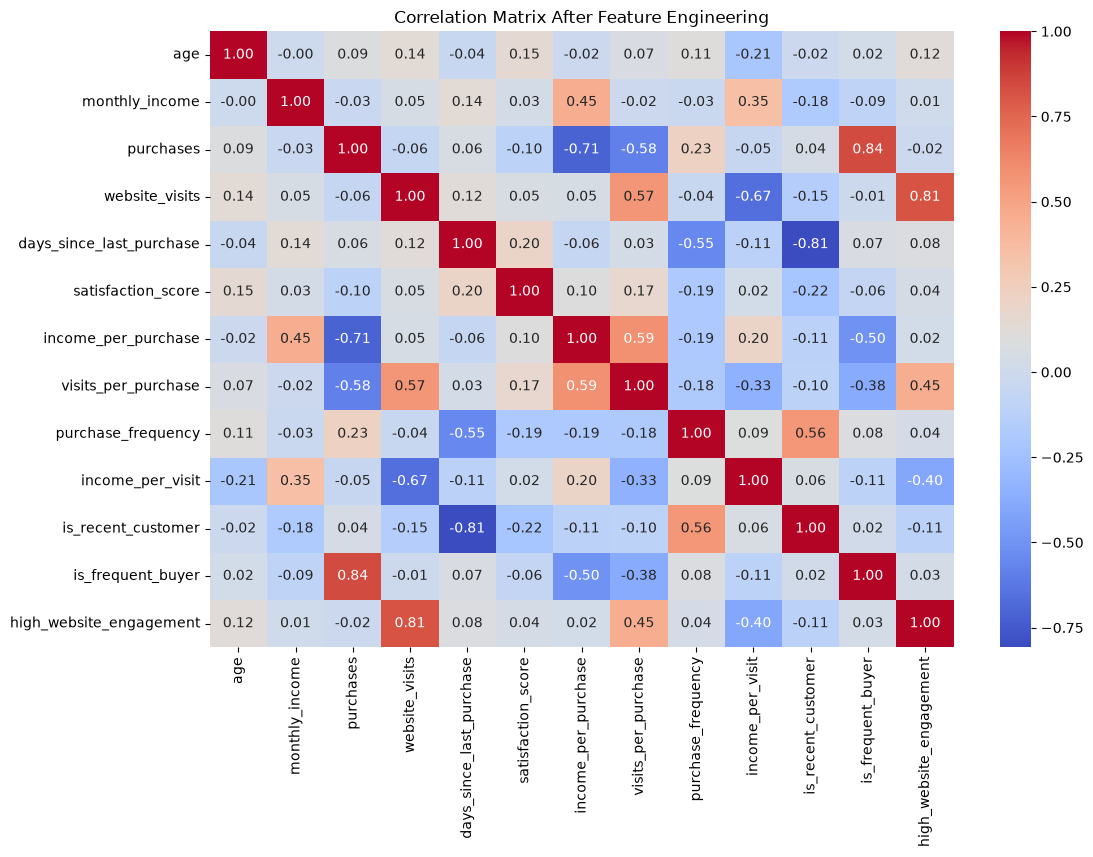

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix After Feature Engineering")
plt.show()

In [32]:
X_fe = X_fe.drop(columns=["customer_id"], errors="ignore")

In [33]:
from sklearn.model_selection import train_test_split

X_train_fe, X_test_fe, y_train_fe, y_test_fe = train_test_split(
    X_fe,
    y_fe,
    test_size=0.2,
    random_state=42
)

In [34]:
numerical_cols_fe = X_train_fe.select_dtypes(
    include="number"
).columns.tolist()

categorical_cols_fe = X_train_fe.select_dtypes(
    include="object"
).columns.tolist()

/tmp/ipykernel_28047/3060827949.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols_fe = X_train_fe.select_dtypes(


In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_pipeline_fe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline_fe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_fe = ColumnTransformer([
    ("num", numeric_pipeline_fe, numerical_cols_fe),
    ("cat", categorical_pipeline_fe, categorical_cols_fe)
])

In [36]:
from sklearn.linear_model import LinearRegression

model_fe = Pipeline([
    ("preprocessor", preprocessor_fe),
    ("regressor", LinearRegression())
])

model_fe.fit(X_train_fe, y_train_fe)

y_pred_fe = model_fe.predict(X_test_fe)

In [38]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

mae_fe = mean_absolute_error(y_test_fe, y_pred_fe)
mse_fe = mean_squared_error(y_test_fe, y_pred_fe)
rmse_fe = np.sqrt(mse_fe)
r2_fe = r2_score(y_test_fe, y_pred_fe)

after_performance = pd.DataFrame({
    "Model": ["After Feature Engineering"],
    "MAE": [mae_fe],
    "MSE": [mse_fe],
    "RMSE": [rmse_fe],
    "R2": [r2_fe]
})

print(after_performance)

                       Model          MAE          MSE         RMSE        R2
0  After Feature Engineering  1791.767484  4257777.915  2063.438372 -0.702008


In [39]:
before_performance


,Model,MAE,MSE,RMSE,R2
0,Linear Regression - Before Feature Engineering,1783.251551,4.309692e+06,2075.979678,-0.72276


In [40]:
performance_comparison = pd.concat(
    [before_performance, after_performance],
    ignore_index=True
)

print(performance_comparison)

                                            Model          MAE           MSE  \
0  Linear Regression - Before Feature Engineering  1783.251551  4.309692e+06   
1                       After Feature Engineering  1791.767484  4.257778e+06   

          RMSE        R2  
0  2075.979678 -0.722760  
1  2063.438372 -0.702008  


In [41]:
performance_comparison.to_csv(
    "before_after_feature_engineering.csv",
    index=False
)